# STGCN 


Adaptación del pipeline STGCN (Yu et al., 2017 — implementación base de [Aguin/STGCN-PyTorch](https://github.com/Aguin/STGCN-PyTorch)) para series de conteo epidemiológico semanal.

- `dataset.npz` — `X_train/Y_train`, `X_val/Y_val`, `X_test/Y_test` ya ventaneados, divididos sin fuga y normalizados.
- `adjacency.npy` — matriz de adyacencia ya alineada al mismo orden de nodos que los tensores.
- `meta.json` — `feature_cols`, `target`, método de normalización (`global`/`revin`).


**Cambios respecto a la versión anterior de este notebook:**
- El modelo acepta **varios canales de entrada** (`casos` + exógenas + `mask`), no solo `casos`.
- La salida es **multi-paso** (`T_out` semanas de una vez), no un único paso `n_pred` semanas adelante.
- Ya no se aplica `log1p` 
- La matriz de adyacencia se usa **tal cual** 


## 1. Paquetes

In [1]:
import random
import math
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.init as init
import torch.nn.functional as F
import matplotlib.pyplot as plt


## 2. Semilla y dispositivo

In [2]:
SEED = 2333
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.backends.cudnn.deterministic = True

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
device


device(type='cpu')

## 3. Configuración: registro de datasets + hiperparámetros del modelo

`DATASETS` es el "campo de configuración" para reutilizar este mismo notebook con distintos datos: cada entrada apunta a las 3 salidas del Notebook 2 (`dataset.npz`, `adjacency.npy`, `meta.json`) de un dataset ya procesado, más un nodo de ejemplo opcional para la visualización final. `DATASET_NAME` decide cuál se usa en esta corrida — todo el resto del notebook es agnóstico al dataset elegido.

**Nota sobre `Kt`:** esta arquitectura (2 bloques ST, cada uno con dos convoluciones temporales de kernel `Kt`) reduce el largo temporal en `4*(Kt-1)` pasos en total. `T_in` (de tu `dataset.npz`) debe ser mayor a eso — con `Kt=3` se necesita `T_in >= 9`. Esto se valida más abajo automáticamente al cargar los datos.


In [3]:
DATASETS = {
    "comunas_medellin": {
        "dataset_npz":   "/kaggle/input/datasets/camijope/mdlldengue/dataset.npz",
        "adjacency_npy": "/kaggle/input/datasets/camijope/mdlldengue/adjacency.npy",
        "meta_json":     "/kaggle/input/datasets/camijope/mdlldengue/meta.json",
        "example_node":  "el_poblado",   # nombre normalizado (minusculas, "_"), para la grafica final
    },
    "departamentos_colombia": {
        "dataset_npz":   "/kaggle/input/.../processed_departamentos/dataset.npz",
        "adjacency_npy": "/kaggle/input/.../processed_departamentos/adjacency.npy",
        "meta_json":     "/kaggle/input/.../processed_departamentos/meta.json",
        "example_node":  "antioquia",
    },
}

DATASET_NAME = "comunas_medellin"   # <-- cambia aqui para reutilizar el notebook con el otro dataset
paths = DATASETS[DATASET_NAME]

save_path = f"/kaggle/working/best_dengue_stgcn_{DATASET_NAME}.pt"

CONFIG = {
    "Ks": 2,               # orden del polinomio de Chebyshev (vecindad espacial)
    "Kt": 2,               # tamaño del kernel temporal
    "blocks": [[1, 8, 16], [16, 8, 32]],   # el primer canal (indice [0][0]) se ajusta mas abajo segun C
    "drop_prob": 0.4,
    "batch_size": 16,
    "epochs": 15,
    "lr": 1e-3,
}

print(f"Dataset activo: {DATASET_NAME}")
print(json.dumps(paths, indent=2))


Dataset activo: comunas_medellin
{
  "dataset_npz": "/kaggle/input/datasets/camijope/mdlldengue/dataset.npz",
  "adjacency_npy": "/kaggle/input/datasets/camijope/mdlldengue/adjacency.npy",
  "meta_json": "/kaggle/input/datasets/camijope/mdlldengue/meta.json",
  "example_node": "el_poblado"
}


## 4. Utilidad opcional: adyacencia por coordenadas

Solo se usa si algún dataset nuevo no trae ya una matriz de adyacencia construida (por ejemplo una red de estaciones de calidad del aire): kernel gaussiano sobre distancia haversine, con umbral — mismo enfoque que usan STGCN/DCRNN para sensores de tráfico. No se llama por defecto, ya que ambos datasets actuales ya traen su adyacencia resuelta desde el Notebook 2.


In [4]:
def build_adjacency_from_coords(lat, lon, sigma=None, epsilon=0.1):
    R = 6371.0
    lat = np.radians(np.asarray(lat))[:, None]
    lon = np.radians(np.asarray(lon))[:, None]
    dlat = lat - lat.T
    dlon = lon - lon.T
    a = np.sin(dlat / 2) ** 2 + np.cos(lat) * np.cos(lat.T) * np.sin(dlon / 2) ** 2
    dist = 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    if sigma is None:
        sigma = dist[dist > 0].std()
    W = np.exp(-(dist ** 2) / (2 * sigma ** 2))
    np.fill_diagonal(W, 0.0)
    W[W < epsilon] = 0.0
    return W.astype(np.float32)


## 5. Carga del dataset ya preprocesado (salidas de los Notebooks 1 y 2)

La adyacencia se usa **tal cual viene** — ya quedó alineada al mismo orden de nodos que los tensores `X`/`Y` en el Notebook 2, así que aquí no hay que reordenarla ni sobrescribirla.


In [5]:
with open(paths["meta_json"]) as f:
    meta = json.load(f)

FEATURE_COLS   = meta["feature_cols"]
TARGET         = meta.get("target", FEATURE_COLS[0])
C              = len(FEATURE_COLS)
NORM_METHOD    = meta["normalization"]["method"]
REVIN_CHANNELS = meta["normalization"].get("revin_channels")

data = np.load(paths["dataset_npz"], allow_pickle=True)
node_order = [str(n) for n in data["master_nodes"]]
n_route = len(node_order)

W = np.load(paths["adjacency_npy"]).astype(np.float32)
assert W.shape == (n_route, n_route), f"Adyacencia {W.shape} no coincide con N={n_route} nodos"

print(f"Dataset            : {DATASET_NAME}")
print(f"Nodos (N)          : {n_route}")
print(f"Canales (C)        : {C} -> {FEATURE_COLS}")
print(f"Normalizacion       : {NORM_METHOD}" + (f" (canales: {REVIN_CHANNELS})" if NORM_METHOD == "revin" else ""))
print(f"Adyacencia          : {W.shape} - densidad: {(W > 0).mean().round(3)}")


Dataset            : comunas_medellin
Nodos (N)          : 21
Canales (C)        : 4 -> ['casos', 'week_sin', 'week_cos', 'mask']
Normalizacion       : global
Adyacencia          : (21, 21) - densidad: 0.361


## 6. Modelo STGCN

Arquitectura base sin cambios respecto al paper/repo original, salvo dos ajustes deliberados:

- **Entrada multi-canal**: el primer bloque acepta `C` canales (no solo 1), para aprovechar las exógenas y la máscara.
- **Salida multi-paso**: `fully_conv_layer`/`output_layer`/`STGCN` reciben `n_pred` (= `T_out`) y devuelven `[B, T_out, N]` en un solo forward, en vez de una única semana.


In [6]:
class align(nn.Module):
    def __init__(self, c_in, c_out):
        super(align, self).__init__()
        self.c_in = c_in
        self.c_out = c_out
        if c_in > c_out:
            self.conv1x1 = nn.Conv2d(c_in, c_out, 1)

    def forward(self, x):
        if self.c_in > self.c_out:
            return self.conv1x1(x)
        if self.c_in < self.c_out:
            return F.pad(x, [0, 0, 0, 0, 0, self.c_out - self.c_in, 0, 0])
        return x


class temporal_conv_layer(nn.Module):
    def __init__(self, kt, c_in, c_out, act="relu"):
        super(temporal_conv_layer, self).__init__()
        self.kt = kt
        self.act = act
        self.c_out = c_out
        self.align = align(c_in, c_out)
        if self.act == "GLU":
            self.conv = nn.Conv2d(c_in, c_out * 2, (kt, 1), 1)
        else:
            self.conv = nn.Conv2d(c_in, c_out, (kt, 1), 1)

    def forward(self, x):
        x_in = self.align(x)[:, :, self.kt - 1:, :]
        if self.act == "GLU":
            x_conv = self.conv(x)
            return (x_conv[:, :self.c_out, :, :] + x_in) * torch.sigmoid(x_conv[:, self.c_out:, :, :])
        if self.act == "sigmoid":
            return torch.sigmoid(self.conv(x) + x_in)
        return torch.relu(self.conv(x) + x_in)


class spatio_conv_layer(nn.Module):
    def __init__(self, ks, c, Lk):
        super(spatio_conv_layer, self).__init__()
        self.Lk = Lk
        self.theta = nn.Parameter(torch.FloatTensor(c, c, ks))
        self.b = nn.Parameter(torch.FloatTensor(1, c, 1, 1))
        self.reset_parameters()

    def reset_parameters(self):
        init.kaiming_uniform_(self.theta, a=math.sqrt(5))
        fan_in, _ = init._calculate_fan_in_and_fan_out(self.theta)
        bound = 1 / math.sqrt(fan_in)
        init.uniform_(self.b, -bound, bound)

    def forward(self, x):
        x_c = torch.einsum("knm,bitm->bitkn", self.Lk, x)
        x_gc = torch.einsum("iok,bitkn->botn", self.theta, x_c) + self.b
        return torch.relu(x_gc + x)


class st_conv_block(nn.Module):
    def __init__(self, ks, kt, n, c, p, Lk):
        super(st_conv_block, self).__init__()
        self.tconv1 = temporal_conv_layer(kt, c[0], c[1], "GLU")
        self.sconv = spatio_conv_layer(ks, c[1], Lk)
        self.tconv2 = temporal_conv_layer(kt, c[1], c[2])
        self.ln = nn.LayerNorm([n, c[2]])
        self.dropout = nn.Dropout(p)

    def forward(self, x):
        x_t1 = self.tconv1(x)
        x_s = self.sconv(x_t1)
        x_t2 = self.tconv2(x_s)
        x_ln = self.ln(x_t2.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)
        return self.dropout(x_ln)


class fully_conv_layer(nn.Module):
    """Proyecta al numero de pasos a predecir (n_pred = T_out), no a un unico valor."""
    def __init__(self, c, n_pred):
        super(fully_conv_layer, self).__init__()
        self.conv = nn.Conv2d(c, n_pred, 1)

    def forward(self, x):
        return self.conv(x)


class output_layer(nn.Module):
    def __init__(self, c, T, n, n_pred):
        super(output_layer, self).__init__()
        self.tconv1 = temporal_conv_layer(T, c, c, "GLU")
        self.ln = nn.LayerNorm([n, c])
        self.tconv2 = temporal_conv_layer(1, c, c, "sigmoid")
        self.fc = fully_conv_layer(c, n_pred)

    def forward(self, x):
        x_t1 = self.tconv1(x)
        x_ln = self.ln(x_t1.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)
        x_t2 = self.tconv2(x_ln)
        return self.fc(x_t2)   # [B, n_pred, 1, N]


class STGCN(nn.Module):
    def __init__(self, ks, kt, bs, T, n, Lk, p, n_pred):
        super(STGCN, self).__init__()
        self.st_conv1 = st_conv_block(ks, kt, n, bs[0], p, Lk)
        self.st_conv2 = st_conv_block(ks, kt, n, bs[1], p, Lk)
        self.output = output_layer(bs[1][2], T - 4 * (kt - 1), n, n_pred)

    def forward(self, x):
        x_st1 = self.st_conv1(x)
        x_st2 = self.st_conv2(x_st1)
        return self.output(x_st2).squeeze(2)   # [B, n_pred, N]


def scaled_laplacian(A):
    n = A.shape[0]
    d = np.sum(A, axis=1)
    L = np.diag(d) - A
    for i in range(n):
        for j in range(n):
            if d[i] > 0 and d[j] > 0:
                L[i, j] /= np.sqrt(d[i] * d[j])
    lam = np.linalg.eigvals(L).max().real
    if lam < 1e-6:
        lam = 1.0   # evita division por cero si la matriz viene toda en 0
    return 2 * L / lam - np.eye(n)


def cheb_poly(L, Ks):
    n = L.shape[0]
    LL = [np.eye(n), L[:]]
    for i in range(2, Ks):
        LL.append(np.matmul(2 * L, LL[-1]) - LL[-2])
    return np.asarray(LL)


## 7. Grafo: Laplaciano escalado + polinomios de Chebyshev

In [7]:
L = scaled_laplacian(W)
Lk = cheb_poly(L, CONFIG["Ks"])
Lk = torch.Tensor(Lk.astype(np.float32)).to(device)
Lk.shape


torch.Size([2, 21, 21])

## 8. Tensores para el modelo

El split train/val/test, las ventanas (`T_in`/`T_out`) y la normalización (`global` o `revin`) ya se resolvieron en el Notebook 2 — aquí solo se lleva `X`/`Y` al formato *channel-first* que espera `Conv2d` (`[B, C, T_in, N]`), sin volver a tocar la escala de los datos (nada de `log1p` ni de recalcular estadísticas: hacerlo aquí de nuevo introduciría una doble normalización).


In [8]:
def to_model_tensors(X, Y, device):
    # X: (B, T_in, N, C)  -> (B, C, T_in, N)
    # Y: (B, T_out, N, 1) -> (B, T_out, N)
    X_t = torch.tensor(X, dtype=torch.float32).permute(0, 3, 1, 2).to(device)
    Y_t = torch.tensor(Y, dtype=torch.float32).squeeze(-1).to(device)
    return X_t, Y_t


x_train, y_train = to_model_tensors(data["X_train"], data["Y_train"], device)
x_val,   y_val   = to_model_tensors(data["X_val"],   data["Y_val"],   device)
x_test,  y_test  = to_model_tensors(data["X_test"],  data["Y_test"],  device)

T_in, T_out = x_train.shape[2], y_train.shape[1]

min_T_in = 4 * (CONFIG["Kt"] - 1) + 1
assert T_in > 4 * (CONFIG["Kt"] - 1), (
    f"T_in={T_in} no alcanza para Kt={CONFIG['Kt']} con esta arquitectura (2 bloques ST). "
    f"Se necesita T_in > {4*(CONFIG['Kt']-1)} (minimo {min_T_in}). "
    f"Vuelve a generar dataset.npz en el Notebook 2 con un T_in mayor, o baja CONFIG['Kt']."
)

print("x_train:", x_train.shape, "-> (B, C, T_in, N)")
print("y_train:", y_train.shape, "-> (B, T_out, N)")


x_train: torch.Size([467, 4, 8, 21]) -> (B, C, T_in, N)
y_train: torch.Size([467, 4, 21]) -> (B, T_out, N)


## 9. DataLoaders

In [9]:
train_data = torch.utils.data.TensorDataset(x_train, y_train)
train_iter = torch.utils.data.DataLoader(train_data, CONFIG["batch_size"], shuffle=True)
val_data = torch.utils.data.TensorDataset(x_val, y_val)
val_iter = torch.utils.data.DataLoader(val_data, CONFIG["batch_size"])
test_data = torch.utils.data.TensorDataset(x_test, y_test)
test_iter = torch.utils.data.DataLoader(test_data, CONFIG["batch_size"])


## 10. Modelo, pérdida, optimizador, scheduler

`MSELoss` sobre los datos ya normalizados (`global` o `revin`, según lo elegido en el Notebook 2). Si más adelante ves que el modelo subestima sistemáticamente los brotes grandes, vale la pena probar una pérdida ponderada o una cabeza de salida Poisson/Binomial-Negativa.


In [10]:
CONFIG["blocks"][0][0] = C   # el primer bloque debe aceptar tantos canales como FEATURE_COLS

model = STGCN(CONFIG["Ks"], CONFIG["Kt"], CONFIG["blocks"], T_in, n_route, Lk, CONFIG["drop_prob"], T_out).to(device)
loss_fn = nn.MSELoss()
optimizer = torch.optim.RMSprop(model.parameters(), lr=CONFIG["lr"])
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=8, gamma=0.7)


## 11. Entrenamiento (con guardado del mejor modelo según validación)

In [11]:
def evaluate_loss(model, loss_fn, data_iter):
    model.eval()
    loss_sum, n = 0.0, 0
    with torch.no_grad():
        for x, y in data_iter:
            y_pred = model(x)
            l = loss_fn(y_pred, y)
            loss_sum += l.item() * y.shape[0]
            n += y.shape[0]
    return loss_sum / n


min_val_loss = np.inf
history = {"train": [], "val": []}

for epoch in range(1, CONFIG["epochs"] + 1):
    model.train()
    l_sum, n = 0.0, 0
    for x, y in train_iter:
        y_pred = model(x)
        l = loss_fn(y_pred, y)
        optimizer.zero_grad()
        l.backward()
        optimizer.step()
        l_sum += l.item() * y.shape[0]
        n += y.shape[0]
    scheduler.step()

    train_loss = l_sum / n
    val_loss = evaluate_loss(model, loss_fn, val_iter)
    history["train"].append(train_loss)
    history["val"].append(val_loss)

    if val_loss < min_val_loss:
        min_val_loss = val_loss
        torch.save(model.state_dict(), save_path)

    if epoch % 5 == 0 or epoch == 1:
        print(f"epoch {epoch:3d} | train loss: {train_loss:.4f} | val loss: {val_loss:.4f}")


epoch   1 | train loss: 0.6760 | val loss: 0.0207
epoch   5 | train loss: 0.2495 | val loss: 0.0322
epoch  10 | train loss: 0.1697 | val loss: 0.0139
epoch  15 | train loss: 0.1461 | val loss: 0.0184


## 12. Cargar el mejor modelo

In [12]:
best_model = STGCN(CONFIG["Ks"], CONFIG["Kt"], CONFIG["blocks"], T_in, n_route, Lk, CONFIG["drop_prob"], T_out).to(device)
best_model.load_state_dict(torch.load(save_path))


<All keys matched successfully>

## 13. Evaluación

Se desnormaliza con las estadísticas guardadas por el Notebook 2 (`mu`/`sd` globales, o `mu_test`/`sd_test` por ventana si el método fue `revin`) y se recorta a 0, porque el modelo puede predecir valores ligeramente negativos sin sentido para conteos de casos. El MAPE se calcula solo sobre observaciones con casos reales ≥ 1, **redondeando primero** los valores reales reconstruidos.


In [13]:
def desnormalizar(Y_norm, split):
    """Y_norm: array en escala normalizada. split: 'train'|'val'|'test'
    (solo importa para 'revin', que guarda estadisticas por ventana y por split)."""
    if NORM_METHOD == "global":
        target_idx = FEATURE_COLS.index(TARGET)
        mu_y = float(data["mu"][0, 0, 0, target_idx])
        sd_y = float(data["sd"][0, 0, 0, target_idx])
        return Y_norm * sd_y + mu_y
    else:  # "revin"
        mu_local = data[f"mu_{split}"]
        sd_local = data[f"sd_{split}"]
        target_pos = int(data["target_pos"])
        mu_y = mu_local[..., target_pos]   # (B,1,N) -> broadcastea contra (B,T_out,N)
        sd_y = sd_local[..., target_pos]
        return Y_norm * sd_y + mu_y


def evaluate_metrics(model, data_iter, split):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for x, y in data_iter:
            preds.append(model(x).cpu().numpy())
            trues.append(y.cpu().numpy())
    preds = np.clip(desnormalizar(np.concatenate(preds), split), 0, None)
    trues = np.clip(desnormalizar(np.concatenate(trues), split), 0, None)

    mae = np.mean(np.abs(preds - trues))
    rmse = np.sqrt(np.mean((preds - trues) ** 2))

    trues_int = np.round(trues)
    mask = trues_int >= 1
    mape = np.mean(np.abs((preds[mask] - trues_int[mask]) / trues_int[mask])) * 100
    n_excluded = (~mask).sum()

    return mae, rmse, mape, n_excluded, preds, trues


test_loss = evaluate_loss(best_model, loss_fn, test_iter)
mae, rmse, mape, n_excluded, preds, trues = evaluate_metrics(best_model, test_iter, "test")

print(f"Test loss (escala normalizada): {test_loss:.4f}")
print(f"MAE:  {mae:.2f} casos")
print(f"RMSE: {rmse:.2f} casos")
print(f"MAPE: {mape:.1f}%  (excluyendo {n_excluded} observaciones con 0 casos reales)")

# Desglose por paso del horizonte (semana +1, +2, ..., +T_out)
print("\nPor paso del horizonte:")
for h in range(T_out):
    p_h, t_h = preds[:, h, :], trues[:, h, :]
    mae_h = np.mean(np.abs(p_h - t_h))
    rmse_h = np.sqrt(np.mean((p_h - t_h) ** 2))
    print(f"  semana +{h+1}: MAE={mae_h:.2f} | RMSE={rmse_h:.2f}")


Test loss (escala normalizada): 0.0101
MAE:  0.70 casos
RMSE: 0.96 casos
MAPE: 39.8%  (excluyendo 7482 observaciones con 0 casos reales)

Por paso del horizonte:
  semana +1: MAE=0.65 | RMSE=0.92
  semana +2: MAE=0.74 | RMSE=0.99
  semana +3: MAE=0.69 | RMSE=0.95
  semana +4: MAE=0.74 | RMSE=0.99


## 14. Baseline de persistencia ingenua (multi-paso) + comparación

El baseline repite, para las `T_out` semanas del horizonte, el último valor de `casos` conocido en la ventana de entrada — así se compara contra algo más exigente que "predecir el promedio".


In [14]:
def get_last_known(X_norm, split):
    """Ultimo valor conocido del target en cada ventana de entrada, desnormalizado
    con las mismas estadisticas (y el mismo split) que usa `desnormalizar` para Y."""
    target_idx = FEATURE_COLS.index(TARGET)
    last_step_norm = X_norm[:, -1, :, target_idx]        # (B, N)
    return desnormalizar(last_step_norm[:, None, :], split)[:, 0, :]   # (B, N)


y_naive = get_last_known(data["X_test"], "test")                       # (B, N)
y_naive_rep = np.clip(np.repeat(y_naive[:, None, :], T_out, axis=1), 0, None)  # (B, T_out, N)

mae_naive = np.mean(np.abs(y_naive_rep - trues))
rmse_naive = np.sqrt(np.mean((y_naive_rep - trues) ** 2))

trues_int = np.round(trues)
mask = trues_int >= 1
mape_naive = np.mean(np.abs((y_naive_rep[mask] - trues_int[mask]) / trues_int[mask])) * 100

print(f"Baseline (persistencia) -> MAE: {mae_naive:.2f} | RMSE: {rmse_naive:.2f} | MAPE: {mape_naive:.1f}%")
print(f"STGCN                   -> MAE: {mae:.2f} | RMSE: {rmse:.2f} | MAPE: {mape:.1f}%")


Baseline (persistencia) -> MAE: 0.56 | RMSE: 1.06 | MAPE: 78.5%
STGCN                   -> MAE: 0.70 | RMSE: 0.96 | MAPE: 39.8%


## 15. Visualización — un nodo de ejemplo

Usa `example_node` de `DATASETS[DATASET_NAME]`, o el primer nodo disponible si no se definió uno. Cambia `horizon_step` (0 a `T_out-1`) para ver otro paso del horizonte.


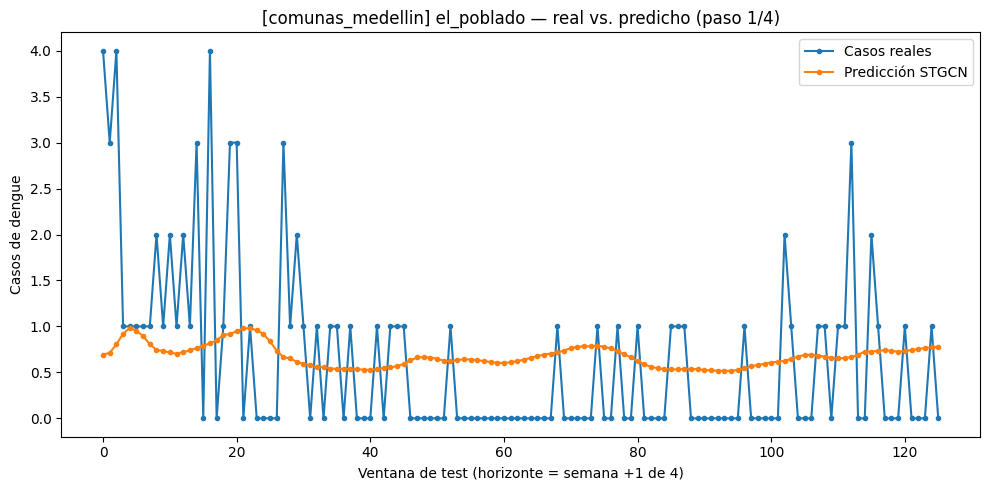

In [15]:
example_node = paths.get("example_node")
node_name = example_node if example_node in node_order else node_order[0]
node_idx = node_order.index(node_name)
horizon_step = 0   # 0 = primera semana predicha del horizonte

plt.figure(figsize=(10, 5))
plt.plot(trues[:, horizon_step, node_idx], label="Casos reales", marker="o", markersize=3)
plt.plot(preds[:, horizon_step, node_idx], label="Predicción STGCN", marker="o", markersize=3)
plt.xlabel(f"Ventana de test (horizonte = semana +{horizon_step+1} de {T_out})")
plt.ylabel("Casos de dengue")
plt.title(f"[{DATASET_NAME}] {node_name} — real vs. predicho (paso {horizon_step+1}/{T_out})")
plt.legend()
plt.tight_layout()
plt.show()
